##Cấu hình, bản đồ


In [9]:
import json
import time
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
GAMMA = 0.95
THETA = 1e-8
MAX_STEPS = 150
EVAL_EPISODES = 100
Q_EPISODES = 12000
SARSA_EPISODES = 12000
MC_EPISODES = 12000
TD_EPISODES = 12000
ALPHA = 0.10
EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY = 0.9995

REWARDS = {
    "step": -1,
    "key": 5,
    "goal": 20,
    "invalid": -2,
    "recreated_key": 5
}
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ACTION_NAMES = ["Up", "Down", "Left", "Right"]
ACTION_ARROWS = {"Up": "↑", "Down": "↓", "Left": "←", "Right": "→"}

MAPS = {
    "Map 1 - Basic": [
        "S..W..G",
        ".W.W.W.",
        ".K.DR..",
        ".W.W.W.",
        "...W..."
    ],
    "Map 2 - Intermediate": [
        "S...W..G",
        ".W..W.W.",
        "..K.W...",
        "....DR..",
        ".W..W.W.",
        "....W...",
        ".W......",
        "....W..."
    ],
    "Map 3 - Advanced": [
        "S....W...G",
        ".W...W.W..",
        "..K..W....",
        "...W.W....",
        ".W...W.W..",
        ".....DR...",
        ".W...W.W..",
        "...W.W....",
        ".W...W....",
        ".....W...."
    ]
}

RESULTS_DIR = Path("Key_Door_Grid_World") / "results"
FIGURES_DIR = Path("Key_Door_Grid_World") / "figures"
MAPS_DIR = Path("Key_Door_Grid_World") / "maps"
for folder in (RESULTS_DIR, FIGURES_DIR, MAPS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)

def validate_map(grid):
    if not grid or not grid[0] or any(len(row) != len(grid[0]) for row in grid):
        raise ValueError("All map rows must have the same non-zero width.")
    cells = "".join(grid)
    for symbol in ("S", "K", "D", "R", "G"):
        if cells.count(symbol) != 1:
            raise ValueError(f"Bản đồ phải chứa chính xác 1 {symbol}")
    allowed = set("S G K D R W .".split())
    if any(char not in allowed for char in cells):
        raise ValueError("Bản đồ chứa ký hiệu không được hỗ trợ")
    return len(grid), len(grid[0])

for name, grid in MAPS.items():
    validate_map(grid)

map_legend = {
    "S": "Start",
    "G": "Goal",
    "K": "Original key",
    "D": "Locked door",
    "R": "One-time key recreation",
    "W": "Wall",
    ".": "Empty cell"
}

## Môi trường KeyDoorEnv


In [10]:
class KeyDoorEnv:
    def __init__(self, grid, rewards=None):
        self.grid = list(grid)
        self.rows, self.cols = validate_map(self.grid)
        self.rewards = dict(REWARDS if rewards is None else rewards)
        self.start = self._find("S")
        self.goal = self._find("G")
        self.key_pos = self._find("K")
        self.door_pos = self._find("D")
        self.recreation_pos = self._find("R")
        self.initial_state = (*self.start, False, False, True)

    def _find(self, symbol):
        for r, row in enumerate(self.grid):
            for c, value in enumerate(row):
                if value == symbol:
                    return r, c
        raise ValueError(f"Thiếu biểu tượng trên bản đồ: {symbol}")

    def is_terminal(self, state):
        return state[:2] == self.goal

    def transition(self, state, action):
        if self.is_terminal(state):
            return state, 0.0, "terminal"
        r, c, has_key, door_open, recreation_available = state
        dr, dc = ACTIONS[int(action)]
        nr, nc = r + dr, c + dc

        if not (0 <= nr < self.rows and 0 <= nc < self.cols):
            return state, self.rewards["invalid"], "invalid"
        tile = self.grid[nr][nc]
        if tile == "W":
            return state, self.rewards["invalid"], "invalid"

        next_has_key = has_key
        next_door_open = door_open
        next_recreation_available = recreation_available
        reward = self.rewards["step"]
        event = "move"

        if tile == "D" and not next_door_open:
            if not next_has_key:
                return state, self.rewards["invalid"], "locked_door"
            next_has_key = False
            next_door_open = True
            event = "door_opened"

        if tile == "K" and not next_has_key and not next_door_open:
            next_has_key = True
            reward += self.rewards["key"]
            event = "original_key_collected"

        if tile == "R" and next_door_open and next_recreation_available and not next_has_key:
            next_has_key = True
            next_recreation_available = False
            reward += self.rewards["recreated_key"]
            event = "key_recreated"

        if tile == "G":
            reward += self.rewards["goal"]
            event = "goal"

        next_state = (nr, nc, next_has_key, next_door_open, next_recreation_available)
        return next_state, reward, event

    def reachable_states(self):
        visited = {self.initial_state}
        queue = deque([self.initial_state])
        while queue:
            state = queue.popleft()
            if self.is_terminal(state):
                continue
            for action in range(len(ACTIONS)):
                next_state, _, _ = self.transition(state, action)
                if next_state not in visited:
                    visited.add(next_state)
                    queue.append(next_state)
        return sorted(visited)

def build_model(env, states):
    state_set = set(states)
    model = {}
    for state in states:
        model[state] = []
        for action in range(len(ACTIONS)):
            next_state, reward, event = env.transition(state, action)
            if next_state not in state_set:
                raise RuntimeError("The model reached a state absent from reachable_states().")
            model[state].append((next_state, reward, event))
    return model

def render_map(grid, ax=None, title=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(max(5, len(grid[0]) * 0.65), max(3, len(grid) * 0.55)))
    ax.imshow(np.zeros((len(grid), len(grid[0]))), cmap="Greys", vmin=0, vmax=3)
    colors = {"S": "#b7e4c7", "G": "#90caf9", "K": "#ffe082", "D": "#ef9a9a", "R": "#ce93d8", "W": "#616161", ".": "#ffffff"}
    for r, row in enumerate(grid):
        for c, tile in enumerate(row):
            ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, facecolor=colors[tile], edgecolor="#999999"))
            ax.text(c, r, tile, ha="center", va="center", fontsize=12, color="black" if tile != "W" else "white", fontweight="bold")
    ax.set_xticks(range(len(grid[0])))
    ax.set_yticks(range(len(grid)))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(False)
    ax.set_title(title or "Key-Door Grid World")
    ax.set_xlim(-0.5, len(grid[0]) - 0.5)
    ax.set_ylim(len(grid) - 0.5, -0.5)
    return ax

## Test môi trường



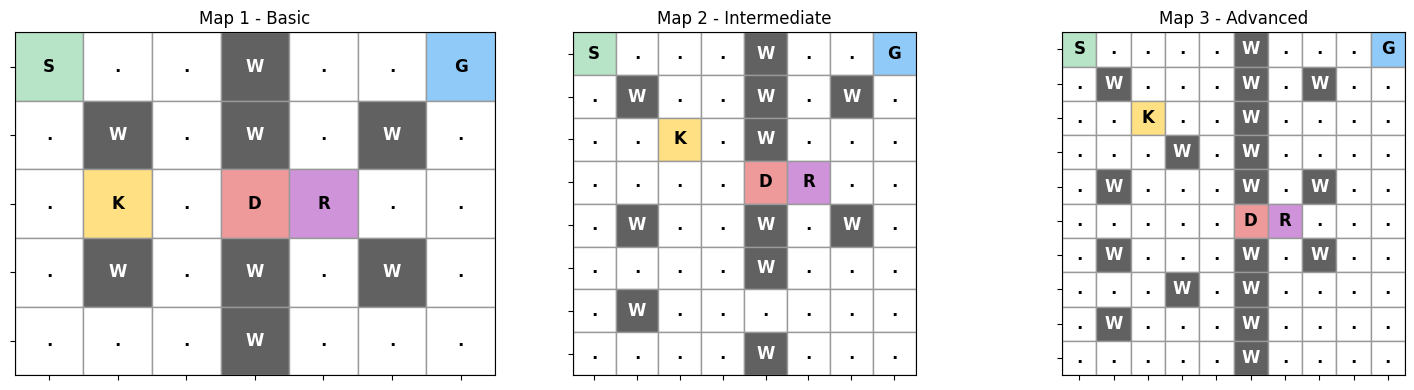

,map,height,width,reachable_states,actions
0,Map 1 - Basic,5,7,66,4
1,Map 2 - Intermediate,8,8,208,4
2,Map 3 - Advanced,10,10,214,4


Environment tests passed: key, door, one-time recreation, no recollection, wall collision.


In [11]:
map_overview = []
for map_name, grid in MAPS.items():
    env = KeyDoorEnv(grid)
    states = env.reachable_states()
    model = build_model(env, states)
    map_overview.append({
        "map": map_name,
        "height": env.rows,
        "width": env.cols,
        "reachable_states": len(states),
        "actions": len(ACTIONS)
    })

fig, axes = plt.subplots(1, len(MAPS), figsize=(5 * len(MAPS), 4))
for ax, (name, grid) in zip(np.atleast_1d(axes), MAPS.items()):
    render_map(grid, ax=ax, title=name)
plt.tight_layout()
plt.show()
display(pd.DataFrame(map_overview))

test_env = KeyDoorEnv(MAPS["Map 1 - Basic"])
assert len(test_env.initial_state) == 5
assert test_env.is_terminal((*test_env.goal, False, True, False))
assert len(test_env.reachable_states()) > 0

key_state, key_reward, key_event = test_env.transition((2, 0, False, False, True), 3)
assert key_state == (2, 1, True, False, True) and key_event == "original_key_collected"

door_state, door_reward, door_event = test_env.transition((2, 2, True, False, True), 3)
assert door_state == (2, 3, False, True, True) and door_event == "door_opened"

recreated_state, recreated_reward, recreated_event = test_env.transition(door_state, 3)
assert recreated_state == (2, 4, True, True, False) and recreated_event == "key_recreated"

no_recollect_state, _, no_recollect_event = test_env.transition((2, 2, False, True, False), 2)
assert no_recollect_state[2] is False and no_recollect_event == "move"

wall_state, wall_reward, wall_event = test_env.transition((0, 2, False, False, True), 3)
assert wall_state == (0, 2, False, False, True) and wall_event == "invalid"
assert wall_reward == test_env.rewards["invalid"]

print("Environment tests passed: key, door, one-time recreation, no recollection, wall collision.")

## Thuật toán


In [12]:
def value_iteration(env, gamma=GAMMA, theta=THETA, max_iterations=10000):
    start = time.perf_counter()
    states = env.reachable_states()
    model = build_model(env, states)
    values = {s: 0.0 for s in states}

    for iteration in range(1, max_iterations + 1):
        delta = 0.0
        updated = values.copy()
        for state in states:
            if env.is_terminal(state):
                updated[state] = 0.0
                continue
            updated[state] = max(reward + gamma * values[next_state]
                                 for next_state, reward, _ in model[state])
            delta = max(delta, abs(updated[state] - values[state]))
        values = updated
        if delta < theta:
            break

    policy = {}
    for state in states:
        if env.is_terminal(state):
            policy[state] = 0
        else:
            action_values = [reward + gamma * values[next_state]
                             for next_state, reward, _ in model[state]]
            policy[state] = int(np.argmax(action_values))
    return policy, {"values": values, "iterations": iteration, "runtime_seconds": time.perf_counter() - start}

def policy_iteration(env, gamma=GAMMA, theta=THETA, max_iterations=1000):
    start = time.perf_counter()
    states = env.reachable_states()
    model = build_model(env, states)
    values = {s: 0.0 for s in states}
    policy = {s: 0 for s in states}

    for iteration in range(1, max_iterations + 1):
        while True:
            delta = 0.0
            updated = values.copy()
            for state in states:
                if env.is_terminal(state):
                    updated[state] = 0.0
                    continue
                next_state, reward, _ = model[state][policy[state]]
                updated[state] = reward + gamma * values[next_state]
                delta = max(delta, abs(updated[state] - values[state]))
            values = updated
            if delta < theta:
                break

        stable = True
        for state in states:
            if env.is_terminal(state):
                continue
            action_values = [reward + gamma * values[next_state]
                             for next_state, reward, _ in model[state]]
            best_action = int(np.argmax(action_values))
            if best_action != policy[state]:
                policy[state] = best_action
                stable = False
        if stable:
            break

    return policy, {"values": values, "iterations": iteration, "runtime_seconds": time.perf_counter() - start}

def epsilon_greedy(Q, state, rng, epsilon):
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))
    values = np.asarray(Q[state], dtype=float)
    best = np.flatnonzero(np.isclose(values, values.max()))
    return int(rng.choice(best))

def q_learning(env, episodes=Q_EPISODES, seed=SEED, alpha=ALPHA, gamma=GAMMA):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    states = env.reachable_states()
    Q = {s: np.zeros(len(ACTIONS), dtype=float) for s in states}
    returns = []
    epsilon = EPSILON_START

    for _ in range(episodes):
        state = env.initial_state
        total = 0.0
        for _ in range(MAX_STEPS):
            action = epsilon_greedy(Q, state, rng, epsilon)
            next_state, reward, _ = env.transition(state, action)
            target = reward if env.is_terminal(next_state) else reward + gamma * np.max(Q[next_state])
            Q[state][action] += alpha * (target - Q[state][action])
            total += reward
            state = next_state
            if env.is_terminal(state):
                break
        returns.append(float(total))
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    policy = {s: int(np.argmax(q)) for s, q in Q.items()}
    return policy, {"Q": Q, "learning_returns": returns, "episodes": episodes, "runtime_seconds": time.perf_counter() - start}

def sarsa(env, episodes=SARSA_EPISODES, seed=SEED, alpha=ALPHA, gamma=GAMMA):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    states = env.reachable_states()
    Q = {s: np.zeros(len(ACTIONS), dtype=float) for s in states}
    returns = []
    epsilon = EPSILON_START

    for _ in range(episodes):
        state = env.initial_state
        action = epsilon_greedy(Q, state, rng, epsilon)
        total = 0.0
        for _ in range(MAX_STEPS):
            next_state, reward, _ = env.transition(state, action)
            total += reward
            if env.is_terminal(next_state):
                target = reward
                Q[state][action] += alpha * (target - Q[state][action])
                break
            next_action = epsilon_greedy(Q, next_state, rng, epsilon)
            target = reward + gamma * Q[next_state][next_action]
            Q[state][action] += alpha * (target - Q[state][action])
            state, action = next_state, next_action
        returns.append(float(total))
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    policy = {s: int(np.argmax(q)) for s, q in Q.items()}
    return policy, {"Q": Q, "learning_returns": returns, "episodes": episodes, "runtime_seconds": time.perf_counter() - start}

def monte_carlo_control(env, episodes=MC_EPISODES, seed=SEED, gamma=GAMMA):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    states = env.reachable_states()
    Q = {s: np.zeros(len(ACTIONS), dtype=float) for s in states}
    returns_sum = {(s, a): 0.0 for s in states for a in range(len(ACTIONS))}
    returns_count = {(s, a): 0 for s in states for a in range(len(ACTIONS))}
    episode_returns = []
    epsilon = EPSILON_START

    for _ in range(episodes):
        state = env.initial_state
        trajectory = []
        total = 0.0
        for _ in range(MAX_STEPS):
            action = epsilon_greedy(Q, state, rng, epsilon)
            next_state, reward, _ = env.transition(state, action)
            trajectory.append((state, action, float(reward)))
            total += reward
            state = next_state
            if env.is_terminal(state):
                break

        G = 0.0
        returns_by_time = [0.0] * len(trajectory)
        for t in range(len(trajectory) - 1, -1, -1):
            G = trajectory[t][2] + gamma * G
            returns_by_time[t] = G

        first_visit = set()
        for (state_t, action_t, _), G_t in zip(trajectory, returns_by_time):
            pair = (state_t, action_t)
            if pair not in first_visit:
                first_visit.add(pair)
                returns_sum[pair] += G_t
                returns_count[pair] += 1
                Q[state_t][action_t] = returns_sum[pair] / returns_count[pair]

        episode_returns.append(float(total))
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    policy = {s: int(np.argmax(q)) for s, q in Q.items()}
    return policy, {"Q": Q, "learning_returns": episode_returns, "episodes": episodes, "runtime_seconds": time.perf_counter() - start}

def td_zero_control(env, episodes=TD_EPISODES, seed=SEED, alpha=ALPHA, gamma=GAMMA):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    states = env.reachable_states()
    model = build_model(env, states)
    values = {state: 0.0 for state in states}
    returns = []
    epsilon = EPSILON_START

    def action_values(state):
        return np.asarray([
            reward + (0.0 if env.is_terminal(next_state) else gamma * values[next_state])
            for next_state, reward, _ in model[state]
        ], dtype=float)

    for _ in range(episodes):
        state = env.initial_state
        total = 0.0
        for _ in range(MAX_STEPS):
            if rng.random() < epsilon:
                action = int(rng.integers(len(ACTIONS)))
            else:
                candidates = np.flatnonzero(np.isclose(action_values(state), action_values(state).max()))
                action = int(rng.choice(candidates))
            next_state, reward, _ = env.transition(state, action)
            target = reward if env.is_terminal(next_state) else reward + gamma * values[next_state]
            values[state] += alpha * (target - values[state])
            total += reward
            state = next_state
            if env.is_terminal(state):
                break
        returns.append(float(total))
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    policy = {}
    for state in states:
        if env.is_terminal(state):
            policy[state] = 0
        else:
            policy[state] = int(np.argmax(action_values(state)))
    return policy, {"values": values, "learning_returns": returns, "episodes": episodes, "runtime_seconds": time.perf_counter() - start}

ALGORITHMS = {
    "Value Iteration": lambda env, seed: value_iteration(env),
    "Policy Iteration": lambda env, seed: policy_iteration(env),
    "Q-learning": lambda env, seed: q_learning(env, seed=seed),
    "SARSA": lambda env, seed: sarsa(env, seed=seed),
    "Monte Carlo": lambda env, seed: monte_carlo_control(env, seed=seed),
    "TD(0) Control": lambda env, seed: td_zero_control(env, seed=seed)
}

## Huấn luyện và đánh giá

In [5]:
def run_episode(env, policy, max_steps=MAX_STEPS):
    state = env.initial_state
    total_return = 0.0
    events = []
    path = [state]
    for _ in range(max_steps):
        if env.is_terminal(state):
            break
        action = policy.get(state, 0)
        next_state, reward, event = env.transition(state, action)
        total_return += reward
        events.append(event)
        state = next_state
        path.append(state)
        if env.is_terminal(state):
            break
    return {
        "return": float(total_return),
        "steps": len(path) - 1,
        "success": env.is_terminal(state),
        "events": events,
        "path": path
    }

def evaluate_policy(env, policy, episodes=EVAL_EPISODES):
    runs = [run_episode(env, policy) for _ in range(episodes)]
    representative = runs[0]
    events = representative["events"]
    path = representative["path"]
    door_open_seen = False
    recollected_original_key = False
    for event in events:
        if event == "door_opened":
            door_open_seen = True
        elif event == "original_key_collected" and door_open_seen:
            recollected_original_key = True

    return {
        "success_rate_pct": 100.0 * np.mean([run["success"] for run in runs]),
        "mean_return": float(np.mean([run["return"] for run in runs])),
        "return_std": float(np.std([run["return"] for run in runs])),
        "mean_steps": float(np.mean([run["steps"] for run in runs])),
        "original_key_collected": "original_key_collected" in events,
        "door_opened": "door_opened" in events,
        "key_recreated": "key_recreated" in events,
        "recreation_consumed": any(path[i-1][4] and not path[i][4] for i in range(1, len(path))),
        "goal_reached": representative["success"],
        "original_key_recollected_after_open": recollected_original_key,
        "representative_episode": representative
    }

def policy_grid(env, policy, path=None):
    path_positions = {(state[0], state[1]) for state in path} if path else set()
    output = []
    for r, row in enumerate(env.grid):
        rendered = []
        for c, tile in enumerate(row):
            if tile != ".":
                rendered.append(tile)
                continue
            candidates = [s for s in policy if s[0] == r and s[1] == c]
            if candidates:
                state = sorted(candidates, key=lambda s: (s[3], s[2], s[4]))[0]
                rendered.append(ACTION_ARROWS[ACTION_NAMES[policy[state]]])
            else:
                rendered.append(".")
        output.append(rendered)
    return output

experiment_rows = []
trained_policies = {}
learning_curves = {}

for map_index, (map_name, grid) in enumerate(MAPS.items()):
    env = KeyDoorEnv(grid)
    states = env.reachable_states()
    for algorithm_name, train_function in ALGORITHMS.items():
        policy, info = train_function(env, SEED + map_index)
        evaluation = evaluate_policy(env, policy)
        representative = evaluation["representative_episode"]
        checks = (
            evaluation["original_key_collected"]
            and evaluation["door_opened"]
            and evaluation["key_recreated"]
            and evaluation["recreation_consumed"]
            and evaluation["goal_reached"]
            and not evaluation["original_key_recollected_after_open"]
        )
        trained_policies[(map_name, algorithm_name)] = policy
        if "learning_returns" in info:
            learning_curves[(map_name, algorithm_name)] = info["learning_returns"]
        experiment_rows.append({
            "map": map_name,
            "algorithm": algorithm_name,
            "reachable_states": len(states),
            "success_rate_pct": evaluation["success_rate_pct"],
            "mean_return": evaluation["mean_return"],
            "return_std": evaluation["return_std"],
            "mean_steps": evaluation["mean_steps"],
            "runtime_seconds": info["runtime_seconds"],
            "training_episodes": info.get("episodes", 0),
            "original_key_collected": evaluation["original_key_collected"],
            "door_opened": evaluation["door_opened"],
            "key_recreated": evaluation["key_recreated"],
            "recreation_consumed": evaluation["recreation_consumed"],
            "goal_reached": evaluation["goal_reached"],
            "all_mechanics_checks_passed": bool(checks)
        })

results_df = pd.DataFrame(experiment_rows)
display(results_df.round(3))

,map,algorithm,reachable_states,success_rate_pct,mean_return,return_std,mean_steps,runtime_seconds,training_episodes,original_key_collected,door_opened,key_recreated,recreation_consumed,goal_reached,all_mechanics_checks_passed
0,Map 1 - Basic,Value Iteration,66,100.0,20.0,0.0,10.0,0.004,0,True,True,True,True,True,True
1,Map 1 - Basic,Policy Iteration,66,100.0,20.0,0.0,10.0,0.057,0,True,True,True,True,True,True
2,Map 1 - Basic,Q-learning,66,100.0,20.0,0.0,10.0,11.295,12000,True,True,True,True,True,True
3,Map 1 - Basic,SARSA,66,100.0,20.0,0.0,10.0,6.265,12000,True,True,True,True,True,True
4,Map 1 - Basic,Monte Carlo,66,100.0,20.0,0.0,10.0,6.851,12000,True,True,True,True,True,True
5,Map 1 - Basic,TD(0) Control,66,100.0,20.0,0.0,10.0,7.426,12000,True,True,True,True,True,True
6,Map 2 - Intermediate,Value Iteration,208,100.0,17.0,0.0,13.0,0.006,0,True,True,True,True,True,True
7,Map 2 - Intermediate,Policy Iteration,208,100.0,17.0,0.0,13.0,0.086,0,True,True,True,True,True,True
8,Map 2 - Intermediate,Q-learning,208,100.0,17.0,0.0,13.0,12.006,12000,True,True,True,True,True,True
9,Map 2 - Intermediate,SARSA,208,100.0,17.0,0.0,13.0,10.787,12000,True,True,True,True,True,True


##So sánh kết quả và trực quan hóa


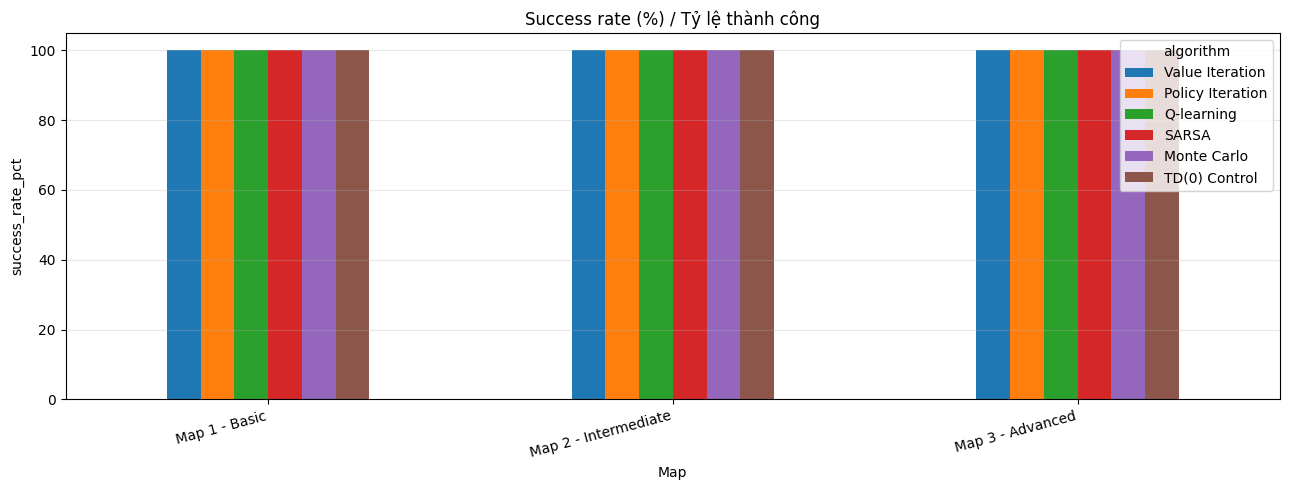

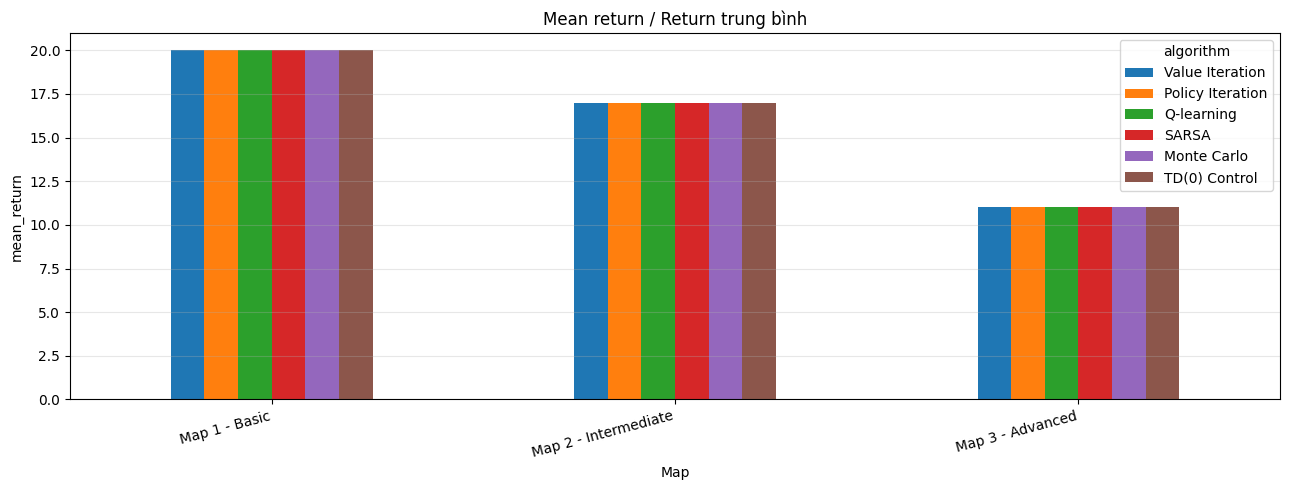

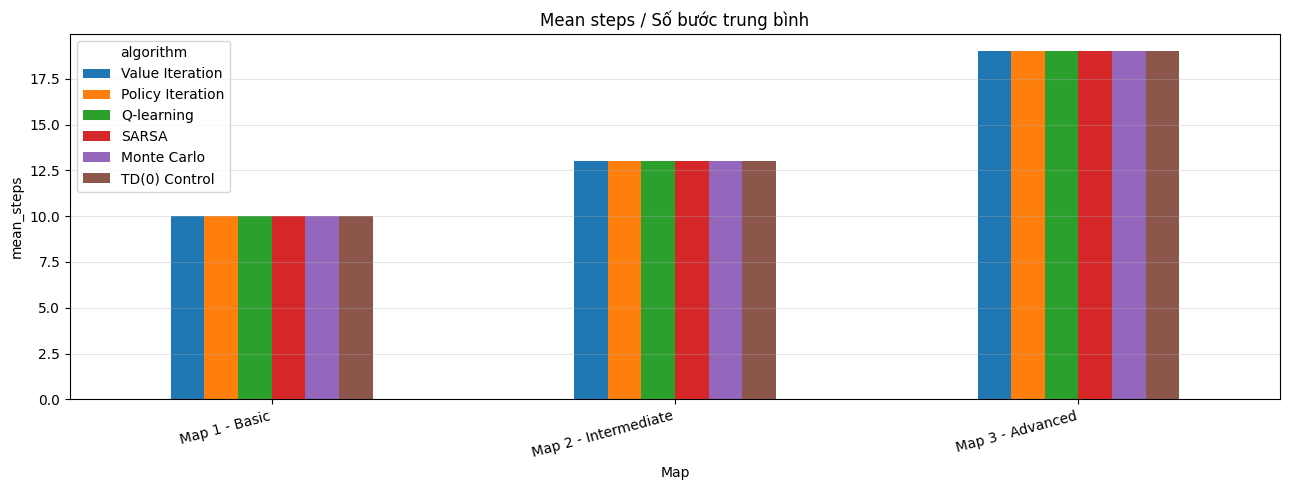

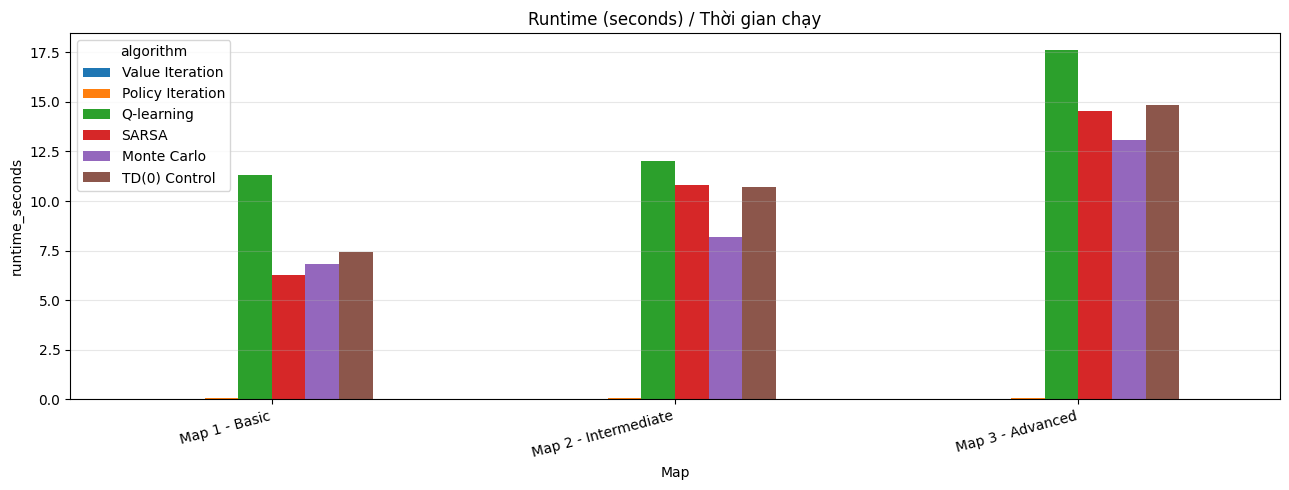

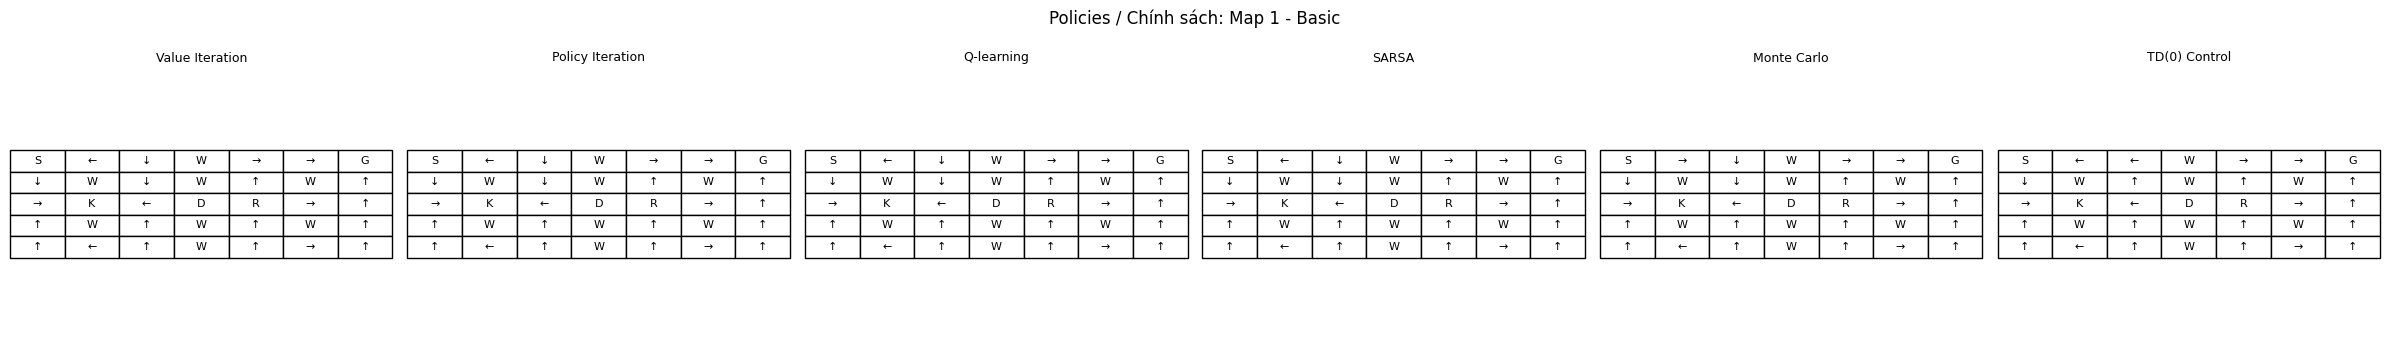

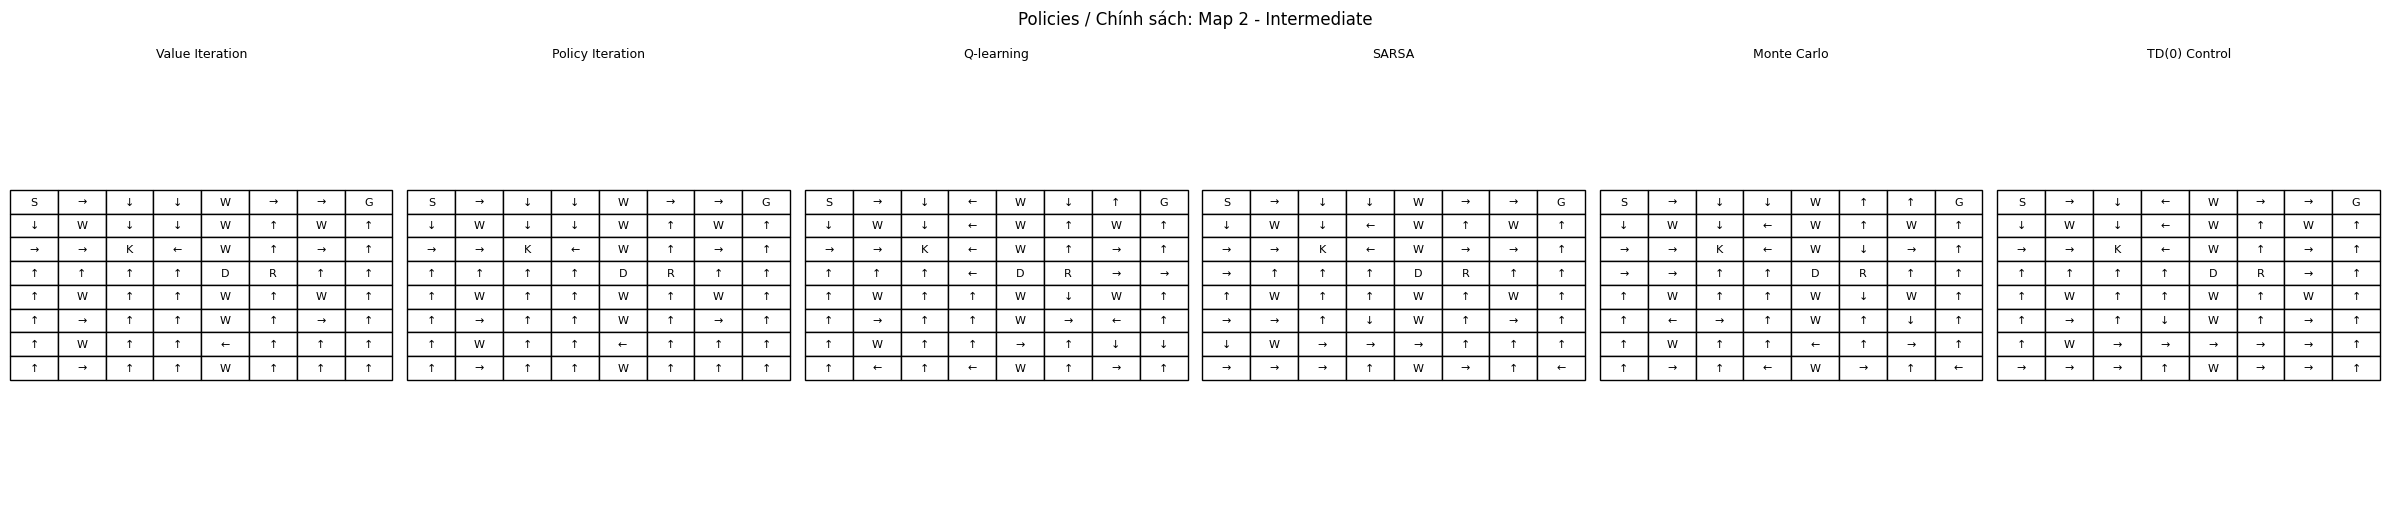

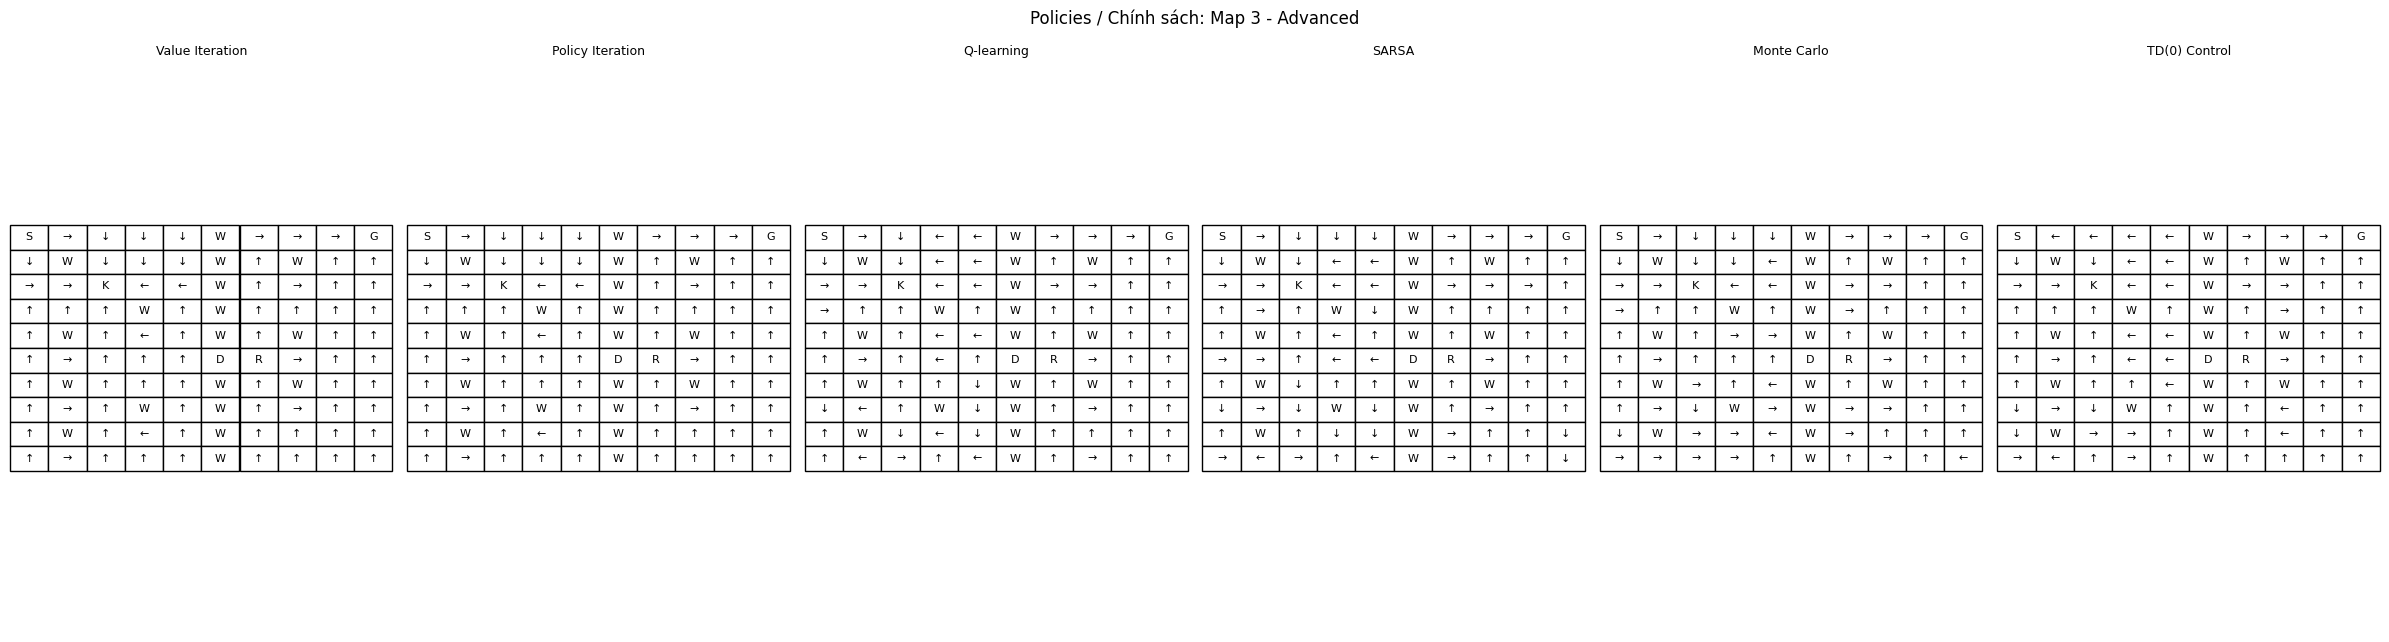

,original_key_collected,door_opened,key_recreated,recreation_consumed,goal_reached,all_mechanics_checks_passed
algorithm,,,,,,
Monte Carlo,True,True,True,True,True,True
Policy Iteration,True,True,True,True,True,True
Q-learning,True,True,True,True,True,True
SARSA,True,True,True,True,True,True
TD(0) Control,True,True,True,True,True,True
Value Iteration,True,True,True,True,True,True


In [6]:
algorithm_order = list(ALGORITHMS.keys())
for metric, title in [
    ("success_rate_pct", "Success rate (%) / Tỷ lệ thành công"),
    ("mean_return", "Mean return / Return trung bình"),
    ("mean_steps", "Mean steps / Số bước trung bình"),
    ("runtime_seconds", "Runtime (seconds) / Thời gian chạy")
]:
    pivot = results_df.pivot(index="map", columns="algorithm", values=metric).reindex(columns=algorithm_order)
    ax = pivot.plot(kind="bar", figsize=(13, 5))
    ax.set_title(title)
    ax.set_xlabel("Map")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()

for map_name, grid in MAPS.items():
    env = KeyDoorEnv(grid)
    available = [name for name in algorithm_order if (map_name, name) in trained_policies]
    fig, axes = plt.subplots(1, len(available), figsize=(4 * len(available), max(3.5, env.rows * 0.65)), squeeze=False)
    for ax, algorithm_name in zip(axes[0], available):
        ax.axis("off")
        table = ax.table(cellText=policy_grid(env, trained_policies[(map_name, algorithm_name)]),
                         cellLoc="center", loc="center")
        table.auto_set_font_size(False)
        table.set_fontsize(8)
        table.scale(1.0, 1.3)
        ax.set_title(algorithm_name, fontsize=9)
    fig.suptitle(f"Policies / Chính sách: {map_name}")
    plt.tight_layout()
    plt.show()

mechanics_summary = results_df.groupby("algorithm")[
    ["original_key_collected", "door_opened", "key_recreated", "recreation_consumed", "goal_reached", "all_mechanics_checks_passed"]
].all()
display(mechanics_summary)

## 7. Phân tích độ ổn định và reward

Phần này là thí nghiệm bổ sung, dùng lại đúng môi trường và các hàm huấn luyện đã định nghĩa ở trên. Nó không tạo một phiên bản môi trường mới.

In [7]:
MULTI_SEEDS = [11, 22, 33, 44, 55]
ROBUSTNESS_ALGORITHMS = {
    "Q-learning": lambda env, seed: q_learning(env, episodes=1000, seed=seed),
    "SARSA": lambda env, seed: sarsa(env, episodes=1000, seed=seed),
    "Monte Carlo": lambda env, seed: monte_carlo_control(env, episodes=1000, seed=seed),
    "TD(0) Control": lambda env, seed: td_zero_control(env, episodes=1000, seed=seed)
}
robustness_rows = []

for map_name, grid in MAPS.items():
    env = KeyDoorEnv(grid)
    for algorithm_name, train_function in ROBUSTNESS_ALGORITHMS.items():
        for seed in MULTI_SEEDS:
            policy, info = train_function(env, seed)
            metrics = evaluate_policy(env, policy, episodes=1)
            robustness_rows.append({
                "map": map_name,
                "algorithm": algorithm_name,
                "seed": seed,
                "success_rate_pct": metrics["success_rate_pct"],
                "mean_return": metrics["mean_return"],
                "mean_steps": metrics["mean_steps"],
                "training_time_seconds": info["runtime_seconds"]
            })

robustness_df = pd.DataFrame(robustness_rows)
robustness_summary = robustness_df.groupby(["map", "algorithm"]).agg(
    success_mean_pct=("success_rate_pct", "mean"),
    success_std_pct=("success_rate_pct", "std"),
    return_mean=("mean_return", "mean"),
    return_std=("mean_return", "std"),
    steps_mean=("mean_steps", "mean"),
    training_time_mean=("training_time_seconds", "mean")
).reset_index().fillna(0)
display(robustness_summary.round(3))

reward_configs = {
    "Baseline": dict(REWARDS),
    "Higher step penalty": {**REWARDS, "step": -2}
}
reward_rows = []
reward_map = MAPS["Map 1 - Basic"]
for config_name, reward_config in reward_configs.items():
    env = KeyDoorEnv(reward_map, rewards=reward_config)
    policy, info = value_iteration(env)
    metrics = evaluate_policy(env, policy, episodes=1)
    reward_rows.append({
        "configuration": config_name,
        "step_reward": reward_config["step"],
        "success": metrics["goal_reached"],
        "return": metrics["mean_return"],
        "steps": metrics["mean_steps"],
        "iterations": info["iterations"],
        "runtime_seconds": info["runtime_seconds"]
    })
reward_comparison_df = pd.DataFrame(reward_rows)
display(reward_comparison_df.round(3))

,map,algorithm,success_mean_pct,success_std_pct,return_mean,return_std,steps_mean,training_time_mean
0,Map 1 - Basic,Monte Carlo,100.0,0.0,20.0,0.0,10.0,0.994
1,Map 1 - Basic,Q-learning,100.0,0.0,20.0,0.0,10.0,1.002
2,Map 1 - Basic,SARSA,100.0,0.0,20.0,0.0,10.0,0.787
3,Map 1 - Basic,TD(0) Control,100.0,0.0,20.0,0.0,10.0,0.819
4,Map 2 - Intermediate,Monte Carlo,100.0,0.0,17.0,0.0,13.0,0.991
5,Map 2 - Intermediate,Q-learning,100.0,0.0,17.0,0.0,13.0,1.851
6,Map 2 - Intermediate,SARSA,100.0,0.0,17.0,0.0,13.0,1.597
7,Map 2 - Intermediate,TD(0) Control,100.0,0.0,17.0,0.0,13.0,1.063
8,Map 3 - Advanced,Monte Carlo,100.0,0.0,11.0,0.0,19.0,1.605
9,Map 3 - Advanced,Q-learning,100.0,0.0,11.0,0.0,19.0,1.717


,configuration,step_reward,success,return,steps,iterations,runtime_seconds
0,Baseline,-1,True,20.0,10.0,12,0.002
1,Higher step penalty,-2,True,10.0,10.0,12,0.002


## 8. Xuất kết quả

In [8]:
results_df.to_csv(RESULTS_DIR / "algorithm_comparison.csv", index=False, encoding="utf-8-sig")
results_df.to_json(RESULTS_DIR / "algorithm_comparison.json", orient="records", force_ascii=False, indent=2)
robustness_df.to_csv(RESULTS_DIR / "robustness_by_seed.csv", index=False, encoding="utf-8-sig")
robustness_summary.to_csv(RESULTS_DIR / "robustness_summary.csv", index=False, encoding="utf-8-sig")
reward_comparison_df.to_csv(RESULTS_DIR / "reward_comparison.csv", index=False, encoding="utf-8-sig")

map_config = {
    "project": "Key-Door Grid World",
    "state": ["row", "col", "has_key", "door_open", "recreation_available"],
    "actions": ACTION_NAMES,
    "rewards": REWARDS,
    "symbols": map_legend,
    "maps": MAPS
}
with open(MAPS_DIR / "map_configurations.json", "w", encoding="utf-8") as file:
    json.dump(map_config, file, ensure_ascii=False, indent=2)

print("Saved outputs:")
for path in sorted(RESULTS_DIR.glob("*")):
    print(path)
print(MAPS_DIR / "map_configurations.json")

Saved outputs:
Key_Door_Grid_World/results/algorithm_comparison.csv
Key_Door_Grid_World/results/algorithm_comparison.json
Key_Door_Grid_World/results/reward_comparison.csv
Key_Door_Grid_World/results/robustness_by_seed.csv
Key_Door_Grid_World/results/robustness_summary.csv
Key_Door_Grid_World/maps/map_configurations.json
